# Pronóstico de dengue y EDA en la costa norte del Perú para planificar el abastecimiento de medicamentos

**Grupo 5 · MIA-203 Redes Neuronales y Aprendizaje Profundo · UNI FIIS**

La idea del proyecto es sencilla: si sabemos con algunas semanas de anticipación cuántos casos de dengue (o de diarrea
en niños) va a haber en cada provincia, se puede mandar la medicina a tiempo. Para eso usamos los datos abiertos del
CDC Perú de 2000 a 2025, el clima de NASA POWER y los índices de El Niño de la NOAA, y entrenamos una LSTM, una GRU y
un Transformer que pronostican hasta 8 semanas adelante en las 14 provincias de Tumbes, Piura y Lambayeque. Al final
probamos ese pronóstico en una simulación de almacén.

Si se abre en Colab, conviene activar la GPU (Entorno de ejecución > Cambiar tipo de entorno > T4 GPU).

## 1. Preparar el entorno
En Colab primero subimos el zip del proyecto (o clonamos el repositorio); la celda lo descomprime y busca la carpeta sola. Si se abre en una computadora, basta con abrir el notebook desde la carpeta `notebooks/`.

In [1]:
import os, sys, glob, pathlib
EN_COLAB = "google.colab" in sys.modules
REPO = "https://github.com/Kysard/dengue-costa-norte.git"   # repositorio del grupo
if EN_COLAB and not glob.glob("**/src/datos.py", recursive=True):
    # Opción A: clonar el repositorio del grupo
    !git clone -q {REPO}
    # Opción B: si no se pudo clonar, subir el zip del proyecto
    if not glob.glob("**/src/datos.py", recursive=True):
        from google.colab import files
        for nombre in files.upload():
            !unzip -q -o "{nombre}"
candidatas = [pathlib.Path("."), pathlib.Path("..")] + [pathlib.Path(p).parents[1] for p in glob.glob("**/src/datos.py", recursive=True)]
raiz = next(c.resolve() for c in candidatas if (c / "src" / "datos.py").exists())
os.chdir(raiz)
sys.path.insert(0, "src")
print("Proyecto listo:", raiz.name)

Proyecto listo: proyecto_grupo5


In [2]:
import time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)

import datos as D, evaluar as E, lineas_base as LB, abastecimiento as AB, graficos as G
import experimentos as X
from interpretar import gradientes_integrados, importancia_por_grupo
from entrenar import DISPOSITIVO, predecir

cfg = X.cargar_config()
SEMILLAS = cfg["semillas"]          # 5 semillas (para probar rápido se puede dejar SEMILLAS = [0])
T0 = time.time()
print("Dispositivo:", DISPOSITIVO, "|", X.info_hardware()["gpu"], "| PyTorch", torch.__version__)

Dispositivo: cpu | sin GPU | PyTorch 2.14.1+cu130


## 2. Datos
Trabajamos con un panel donde cada fila es una provincia en una semana epidemiológica. Lo armamos con `src/construir_dataset.py` juntando los casos del CDC, el clima y El Niño (el detalle de fuentes está en `data/README.md` y en el Excel).

In [3]:
panel = X.cargar_panel()
print(f"{panel.shape[0]:,} filas x {panel.shape[1]} columnas | {panel.ubigeo_prov.nunique()} provincias | "
      f"{panel.ano.min()}-{panel.ano.max()}")
print(f"Casos de dengue: {panel.dengue_total.sum():,} | episodios de EDA en menores de 5 años: {panel.eda_men5.sum():,}")
panel.head(3)

18,998 filas x 29 columnas | 14 provincias | 2000-2025
Casos de dengue: 342,671 | episodios de EDA en menores de 5 años: 1,447,934


,ubigeo_prov,departamento,provincia,ano,semana,fecha_inicio,dengue_ssa,dengue_csa,dengue_grave,dengue_total,...,t2m_max,t2m_min,precip_mm,hr_media,nino12_anom,nino12_sst,oni,poblacion,inc_dengue_100k,inc_eda_100k
0,1401,LAMBAYEQUE,CHICLAYO,2000,1,2000-01-02,0,0,0,0,...,23.10,19.73,0.13,86.41,-0.59,23.93,-1.47,684116,0.0,67.679
1,1401,LAMBAYEQUE,CHICLAYO,2000,2,2000-01-09,0,0,0,0,...,23.10,19.79,0.26,87.34,-0.59,23.93,-1.47,684116,0.0,62.562
2,1401,LAMBAYEQUE,CHICLAYO,2000,3,2000-01-16,0,0,0,0,...,23.13,19.93,1.66,87.71,-0.59,23.93,-1.47,684116,0.0,61.685


In [4]:
panel.groupby("departamento")[["dengue_total", "eda_men5"]].sum().sort_values("dengue_total", ascending=False)

,dengue_total,eda_men5
departamento,,
PIURA,239078,888611
LAMBAYEQUE,57061,463248
TUMBES,46532,96075


## 3. Exploración
Antes de entrenar nada, miramos las series, en qué meses suben los casos y con cuánto retraso responde el dengue al clima.

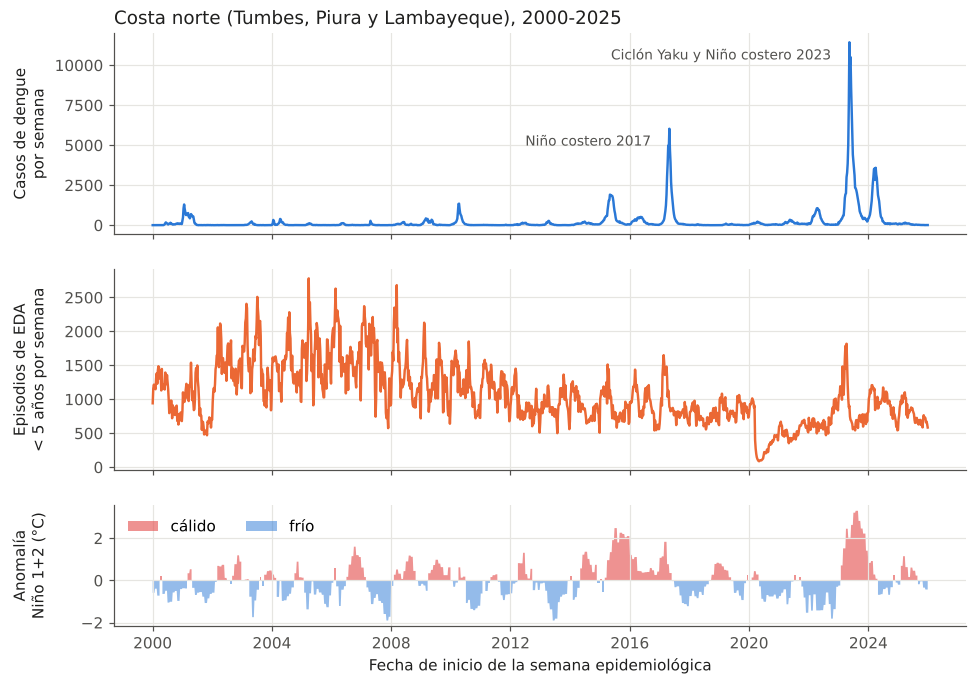

In [5]:
G.serie_y_enso(panel); plt.show()

Se ven claramente las dos grandes epidemias de dengue, 2017 y 2023, y en las dos el mar frente a la costa estaba más caliente de lo normal (Niño costero). La EDA en niños es más pareja; la caída de 2020-2021 es por la pandemia, cuando la gente dejó de ir a los establecimientos.

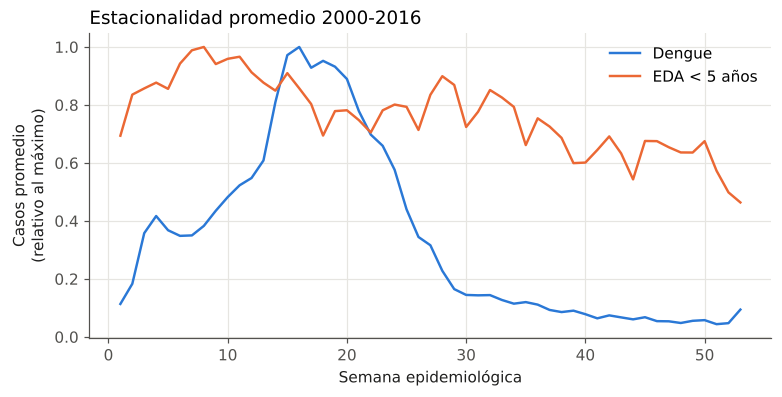

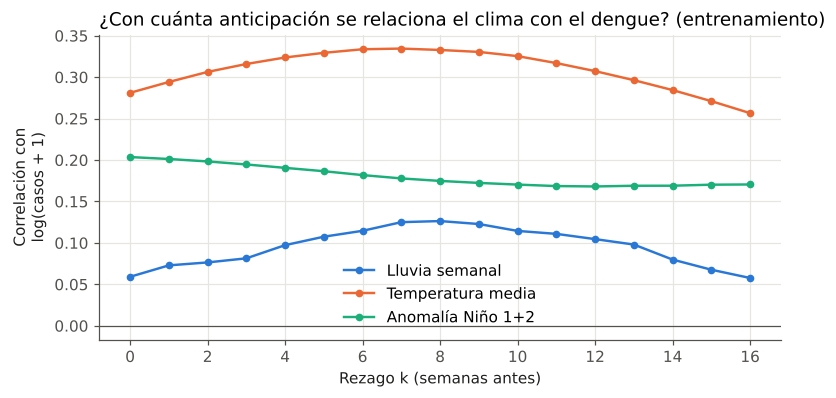

In [6]:
G.estacionalidad(panel); plt.show()
df_den = D.preparar(panel, "dengue")
G.correlacion_rezagos(df_den); plt.show()

El dengue llega a su punto más alto alrededor de la semana 16 (abril) y la EDA en la semana 8 (febrero). La temperatura y la lluvia se relacionan más con los casos de 6 a 8 semanas después, que es más o menos lo que demora el ciclo del zancudo. Por eso le damos al modelo 26 semanas de historia.

## 4. Partición temporal
- Entrenamiento: 2000-2016. Validación: 2017-2020 (para la parada temprana). Prueba: 2021-2025 (no se toca hasta el final).
- Cada ejemplo son 26 semanas de una provincia y el modelo tiene que adivinar las 8 siguientes. Si las 8 semanas caen entre dos periodos, ese ejemplo no se usa, así no se filtra información del futuro.
- Las variables se estandarizan solo con los datos de entrenamiento y lo que se pronostica es log(casos + 1).
- Los índices de El Niño entran con el retraso con que se publican: cada semana usa el Niño 1+2 del mes anterior y el ONI centrado dos meses antes. Así el modelo solo ve lo que de verdad se conocía al momento de pronosticar.

In [7]:
d = X.preparar(panel, "dengue", cfg)
umb = E.umbrales_alerta(d["df"], cfg["alerta"]["percentil"])
print("Variables de entrada:", d["variables"])
pd.DataFrame({c: [len(d[k].X), int(d[k].P.max()) + 1] for c, k in [("entrenamiento", "tr"), ("validación", "va"), ("prueba", "te")]},
             index=["ventanas", "provincias"])

Variables de entrada: ['y', 'sin_sem', 'cos_sem', 't2m_media', 't2m_max', 't2m_min', 'precip_log', 'hr_media', 'nino12_anom', 'oni']


,entrenamiento,validación,prueba
ventanas,11956,2828,3556
provincias,14,14,14


## 5. Líneas base
Para saber si las redes sirven de algo, las comparamos con cuatro métodos más simples:
- **Persistencia:** suponer que las próximas semanas serán iguales a la última.
- **Canal endémico:** la mediana de esa misma semana en los 5 años anteriores. Es lo que usa el MINSA para vigilar y es como planificar "con lo histórico".
- **ARIMA + Fourier:** un ARIMA(2,0,1) con estacionalidad anual, ajustado por provincia solo con el entrenamiento.
- **Random forest:** con las últimas 8 semanas de todas las variables.

Medimos el MAE y el RMSE en casos (promedio de los 8 horizontes), el MAE en escala log y el F1 para avisar con 4 semanas de anticipación que una semana va a estar por encima del percentil 90 de los últimos 5 años. La columna `MAE_val` es el error en validación (2017-2020), que es el que miramos para tomar decisiones; las demás columnas son del conjunto de prueba.

In [8]:
filas_b, preds_b, tiempos_b = X.correr_lineas_base(d, cfg, umb, SEMILLAS)
E.resumen_semillas(filas_b)[0]

,MAE_val,MAE,RMSE,MAE_log,F1
modelo,,,,,
Persistencia,17.1 ± 0.0,38.5 ± 0.0,171.7 ± 0.0,0.647 ± 0.000,0.807 ± 0.000
Canal endémico (5 años),25.3 ± 0.0,56.0 ± 0.0,218.1 ± 0.0,1.634 ± 0.000,0.008 ± 0.000
ARIMA + Fourier,12.7 ± 0.0,34.5 ± 0.0,161.6 ± 0.0,0.646 ± 0.000,0.757 ± 0.000
Random forest,11.3 ± 0.0,29.9 ± 0.2,149.3 ± 0.7,0.612 ± 0.001,0.803 ± 0.003


## 6. LSTM, GRU y Transformer
- A cada semana de la ventana le pegamos un *embedding* de la provincia, para que un solo modelo aprenda las 14.
- LSTM y GRU: 2 capas de 64 unidades. Transformer: encoder de 2 capas, d = 64 y 4 cabezas de atención.
- En vez de pronosticar los casos directamente, la red aprende cuánto van a cambiar respecto a la última semana: $\hat y_{t+h} = y_t + f_\theta(x)_h$, con $y = \log(1 + \text{casos})$. Esto lo probamos después en la ablación.
- Pérdida: $\mathcal{L} = \frac{1}{NH}\sum_i\sum_h (y_{i,t+h} - \hat y_{i,t+h})^2$. Optimizador AdamW (lr = 0.001), lotes de 256 y parada temprana con paciencia de 8 épocas.
- Cada red se entrena con 5 semillas y reportamos media ± desviación estándar.

Entrenamiento terminado en 11.7 min


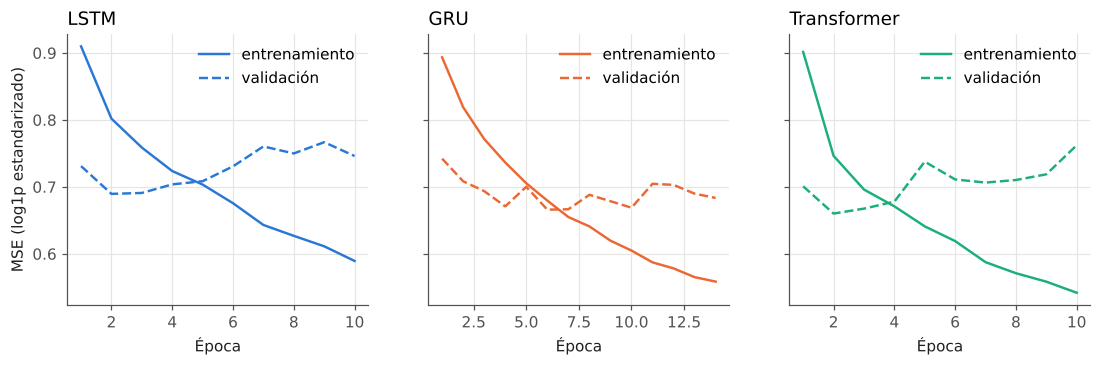

In [9]:
t = time.time()
filas_r, preds_r, infos_r, mejores_r = X.correr_redes(d, cfg, umb, SEMILLAS, list(cfg["modelos"]), "dengue",
                                                      carpeta_pesos="results/pesos")
print(f"Entrenamiento terminado en {(time.time() - t) / 60:.1f} min")
G.curvas_entrenamiento([i for i in infos_r if i["semilla"] == SEMILLAS[0]], "dengue"); plt.show()

In [10]:
tabla_den, agg_den = E.resumen_semillas(filas_b + filas_r)
tabla_den.to_csv("results/tablas/dengue_comparacion.csv")
pd.DataFrame(filas_b + filas_r).to_csv("results/tablas/dengue_comparacion_por_semilla.csv", index=False)
tabla_den

,MAE_val,MAE,RMSE,MAE_log,F1
modelo,,,,,
Persistencia,17.1 ± 0.0,38.5 ± 0.0,171.7 ± 0.0,0.647 ± 0.000,0.807 ± 0.000
Canal endémico (5 años),25.3 ± 0.0,56.0 ± 0.0,218.1 ± 0.0,1.634 ± 0.000,0.008 ± 0.000
ARIMA + Fourier,12.7 ± 0.0,34.5 ± 0.0,161.6 ± 0.0,0.646 ± 0.000,0.757 ± 0.000
Random forest,11.3 ± 0.0,29.9 ± 0.2,149.3 ± 0.7,0.612 ± 0.001,0.803 ± 0.003
LSTM,11.1 ± 0.8,31.8 ± 0.8,157.0 ± 6.5,0.605 ± 0.011,0.809 ± 0.007
GRU,11.1 ± 0.5,31.7 ± 0.9,151.9 ± 4.9,0.619 ± 0.012,0.806 ± 0.007
Transformer,10.9 ± 0.5,29.8 ± 0.9,147.8 ± 5.0,0.607 ± 0.022,0.808 ± 0.008


## 7. Error según cuántas semanas adelante se pronostica
Para comprar y repartir medicamentos no sirve mucho acertar solo la semana siguiente; lo que importa es tener el número con varias semanas de margen.

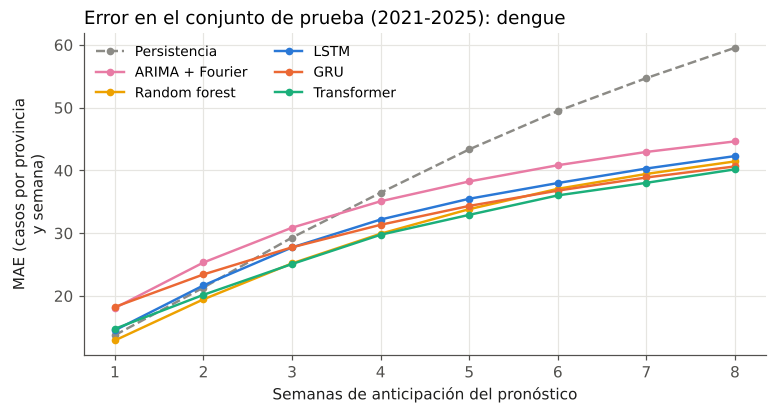

Reducción del MAE de la LSTM frente a la persistencia: 1 sem: -6 %, 4 sem: 12 %, 8 sem: 29 %


,Persistencia,ARIMA + Fourier,Random forest,LSTM,GRU,Transformer
horizonte,,,,,,
1,13.8,18.1,12.9,14.5,18.3,14.8
2,21.3,25.3,19.5,21.7,23.4,20.2
3,29.3,30.9,25.2,27.7,27.8,25.1
4,36.4,35.1,29.9,32.2,31.3,29.8
5,43.4,38.2,33.8,35.5,34.3,32.9
6,49.5,40.8,37.1,38.0,36.8,36.0
7,54.7,42.9,39.4,40.3,38.9,38.0
8,59.5,44.6,41.4,42.3,40.6,40.2


In [11]:
todos = {**preds_b, **preds_r}
por_h = {X.NOMBRES[k]: E.metricas_por_horizonte(d["te"].Y, todos[k][1])
         for k in ["persistencia", "sarimax", "random_forest", "lstm", "gru", "transformer"]}
G.error_por_horizonte(por_h, "dengue", "dengue"); plt.show()
h = pd.DataFrame({k: v.set_index("horizonte").MAE for k, v in por_h.items()})
h.to_csv("results/tablas/dengue_mae_por_horizonte.csv")
mejora = 100 * (1 - h["LSTM"] / h["Persistencia"])
print("Reducción del MAE de la LSTM frente a la persistencia: " +
      ", ".join(f"{k} sem: {v:.0f} %" for k, v in mejora.loc[[1, 4, 8]].items()))
h.round(1)

## 8. Ablación de la LSTM
Volvemos a entrenar la LSTM quitando una cosa a la vez (el clima, El Niño, ambos, o la conexión residual), con las mismas semillas y la misma partición, para ver qué parte aporta realmente.

Ablación terminada en 5.4 min


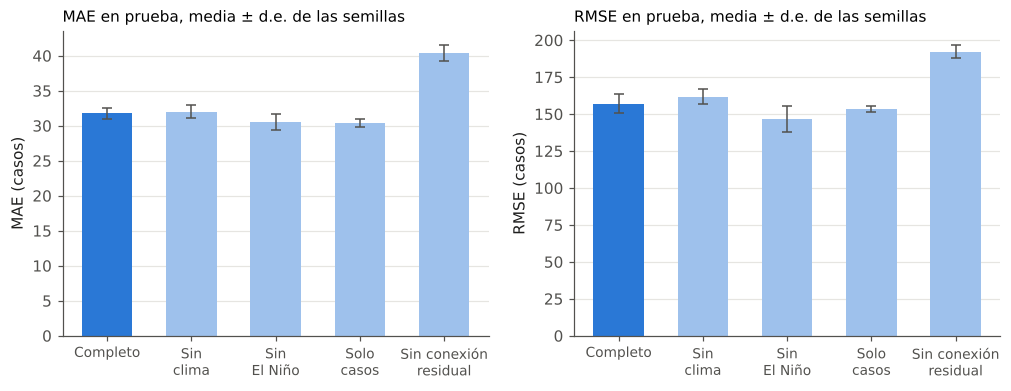

MAE_val            MAE            RMSE        MAE_log            F1       
                mean    std    mean    std     mean    std    mean    std   mean    std
variante                                                                               
completo      11.102  0.837  31.805  0.790  156.973  6.509   0.605  0.011  0.809  0.007
sin_clima     11.697  0.574  31.993  0.899  161.627  5.027   0.602  0.008  0.819  0.006
sin_enso      11.078  0.649  30.524  1.165  146.629  8.762   0.611  0.018  0.808  0.012
solo_casos    11.239  0.421  30.362  0.586  153.543  2.053   0.589  0.008  0.826  0.007
sin_residual  14.614  0.756  40.364  1.118  192.274  4.222   0.722  0.031  0.739  0.024

In [12]:
t = time.time()
filas_lstm = [f for f in filas_r if f["modelo"] == "LSTM"]
filas_ab = X.correr_ablaciones(panel, "dengue", cfg, SEMILLAS, filas_lstm)
ablac = pd.DataFrame(filas_ab).groupby("variante", sort=False)[["MAE_val", "MAE", "RMSE", "MAE_log", "F1"]].agg(["mean", "std"])
ablac.to_csv("results/tablas/dengue_ablacion.csv")
print(f"Ablación terminada en {(time.time() - t) / 60:.1f} min")
G.ablacion(ablac, "dengue"); plt.show()
ablac.round(3)

## 9. ¿Qué está mirando la LSTM? Gradientes integrados
Con gradientes integrados medimos cuánto pesa cada variable y cada semana de la ventana en el pronóstico a 4 semanas. Usamos la LSTM con menor pérdida de validación y 1000 ventanas de prueba al azar.

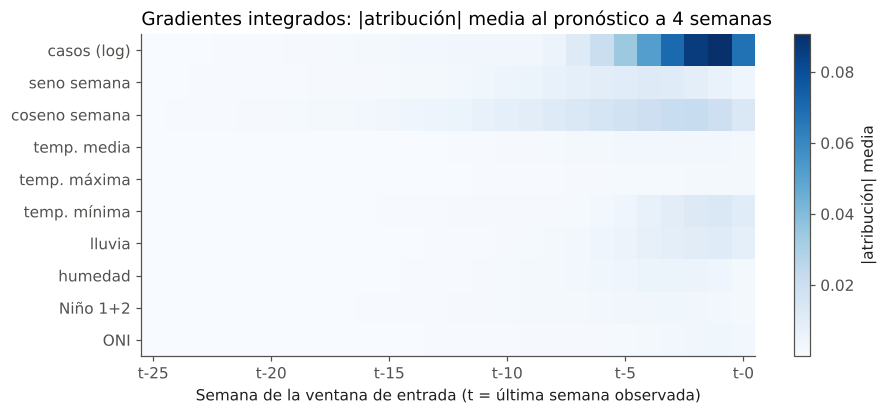

Historia de casos    45.2
Estacionalidad       29.6
Clima                20.0
El Niño               5.2
Name: % de la atribución, dtype: float64

In [13]:
_, lstm_mejor, info_mejor = mejores_r["lstm"]
rng = np.random.default_rng(0)
muestra = rng.choice(len(d["te"].X), size=min(1000, len(d["te"].X)), replace=False)
attr = gradientes_integrados(lstm_mejor, d["te"].X[muestra], d["te"].P[muestra], salida=3, pasos=32)
G.mapa_atribuciones(attr, d["variables"], "dengue"); plt.show()
grupos = {"Historia de casos": D.F_HISTORIA[:1], "Estacionalidad": D.F_HISTORIA[1:], "Clima": D.F_CLIMA, "El Niño": D.F_ENSO}
imp = pd.Series(importancia_por_grupo(attr, d["variables"], grupos), name="% de la atribución").round(1)
imp.to_csv("results/tablas/dengue_importancia_grupos.csv"); imp

## 10. ¿Dónde se equivoca?
Revisamos el error por provincia y separamos las semanas normales de las semanas de alerta.

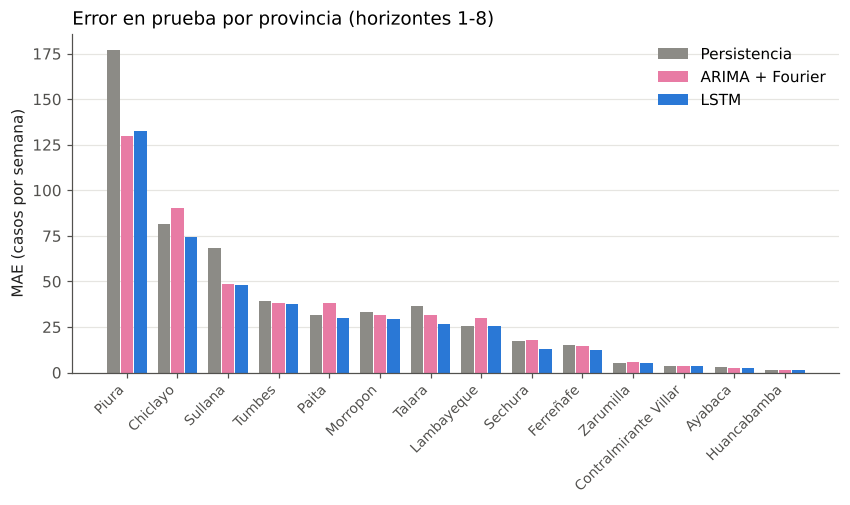

,MAE semanas normales,MAE semanas de alerta
modelo,,
Persistencia,7.0,117.7
ARIMA + Fourier,4.4,119.8
Random forest,4.4,100.2
LSTM,4.3,109.1


In [14]:
te = d["te"]
nombres_prov = d["df"].groupby("prov_idx").provincia.first()
err = {}
for k in ["persistencia", "sarimax", "lstm"]:
    e = np.abs(E.a_casos(te.Y) - E.a_casos(todos[k][1])).mean(1)
    err[X.NOMBRES[k]] = pd.Series(e).groupby(te.P).mean()
err = pd.DataFrame(err); err.index = nombres_prov.loc[err.index].values
err = err.sort_values("LSTM", ascending=False)
G.error_por_provincia(err, "dengue"); plt.show()

anios = d["df"].ano.to_numpy()[te.origen + 4]
u = np.array([umb.get((int(p), int(a)), 1) for p, a in zip(te.P, anios)])
alerta = E.a_casos(te.Y[:, 3]) > u
filas = []
for k in ["persistencia", "sarimax", "random_forest", "lstm"]:
    e4 = np.abs(E.a_casos(te.Y[:, 3]) - E.a_casos(todos[k][1][:, 3]))
    filas.append({"modelo": X.NOMBRES[k], "MAE semanas normales": e4[~alerta].mean(), "MAE semanas de alerta": e4[alerta].mean()})
pd.DataFrame(filas).set_index("modelo").round(1)

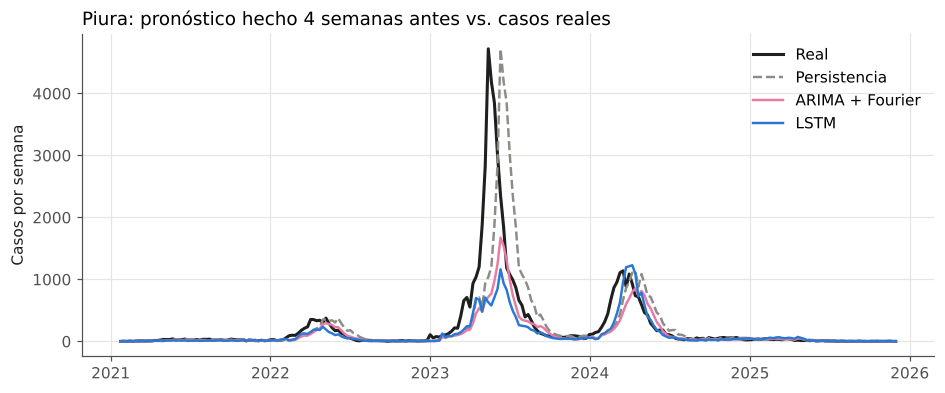

In [15]:
# Piura: pronóstico hecho con 4 semanas de anticipación, 2021-2025
p_piura = int(d["df"].loc[d["df"].provincia == "PIURA", "prov_idx"].iloc[0])
idx = np.where(te.P == p_piura)[0]; idx = idx[np.argsort(te.origen[idx])]
fechas = pd.to_datetime(d["df"].fecha_inicio.to_numpy()[te.origen[idx] + 4])
G.pronostico_provincia(fechas, E.a_casos(te.Y[idx, 3]),
                       {"Persistencia": E.a_casos(todos["persistencia"][1][idx, 3]),
                        "ARIMA + Fourier": E.a_casos(todos["sarimax"][1][idx, 3]),
                        "LSTM": E.a_casos(todos["lstm"][1][idx, 3])}, "PIURA", 4, "dengue"); plt.show()

## 11. Del pronóstico al almacén
Aquí entra la parte de cadena de suministro. Simulamos el almacén de cada provincia entre 2021 y 2025 con una política de **stock base**: cada semana se pide lo que haga falta para cubrir el pronóstico de las próximas 4 semanas (lo que demora en llegar el pedido) más un stock de seguridad. Ese stock de seguridad es 1.65 veces la desviación del error del pronóstico en validación. Un "tratamiento" es lo que necesita un caso (ver la hoja `Kit_medicamentos` del Excel).

Comparamos cuatro formas de planificar: con el canal endémico, con el random forest, con la LSTM y con un pronóstico perfecto como referencia.

In [16]:
lead, z = cfg["abastecimiento"]["lead"], cfg["abastecimiento"]["z"]
pol = {"Canal endémico (5 años)": "canal_endemico", "Random forest": "random_forest", "LSTM": "lstm"}
pron = {k: todos[v][1] for k, v in pol.items()}
ss = {k: AB.stock_seguridad(d["va"], todos[v][0], lead, z) for k, v in pol.items()}
pron["Pronóstico perfecto"] = te.Y; ss["Pronóstico perfecto"] = {}
sim = AB.simular_politicas(te, pron, ss, lead)
sim.to_csv("results/tablas/dengue_abastecimiento.csv", index=False)
sim.set_index("politica").round(1)

,nivel_servicio_%,tratamientos_no_atendidos,semanas_con_quiebre_%,inventario_promedio_semanal
politica,,,,
Canal endémico (5 años),44.9,107467.6,26.0,5340.1
Random forest,75.3,48111.3,14.8,2739.8
LSTM,71.9,54787.3,14.4,2897.1
Pronóstico perfecto,100.0,0.0,0.0,0.7


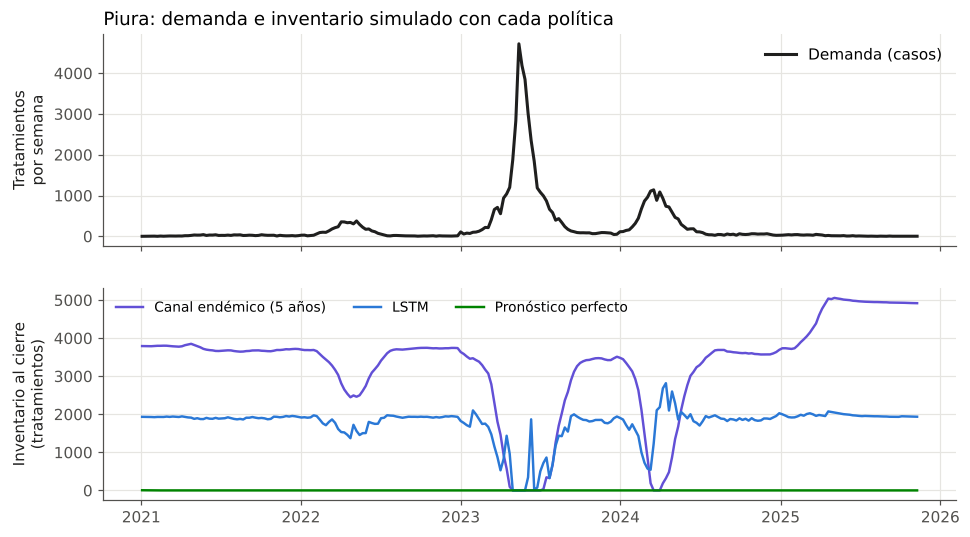

Planificando con la LSTM quedan 52,680 tratamientos menos sin atender que con el canal endémico.
Con el kit ambulatorio (20 tabletas de paracetamol y 5 sobres de SRO por caso) serían unas 1,053,607 tabletas y 263,402 sobres que habrían faltado.


In [17]:
inv = {}
for nombre in ["Canal endémico (5 años)", "LSTM", "Pronóstico perfecto"]:
    orig, dem, r = AB.serie_provincia(te, pron[nombre], p_piura, ss[nombre].get(p_piura, 0.0), lead)
    inv[nombre] = r["serie_inventario"]
G.simulacion_stock(pd.to_datetime(d["df"].fecha_inicio.to_numpy()[orig + 1]), dem, inv, "PIURA"); plt.show()

s = sim.set_index("politica")
dif = s.loc["Canal endémico (5 años)", "tratamientos_no_atendidos"] - s.loc["LSTM", "tratamientos_no_atendidos"]
print(f"Planificando con la LSTM quedan {dif:,.0f} tratamientos menos sin atender que con el canal endémico.")
print(f"Con el kit ambulatorio (20 tabletas de paracetamol y 5 sobres de SRO por caso) serían unas "
      f"{20 * dif:,.0f} tabletas y {5 * dif:,.0f} sobres que habrían faltado.")

## 12. Segunda enfermedad: EDA en menores de 5 años
Repetimos lo mismo con la EDA. Usamos solo menores de 5 años porque, desde la semana 16 de 2024, el archivo del CDC ya no trae los casos de mayores de 5.

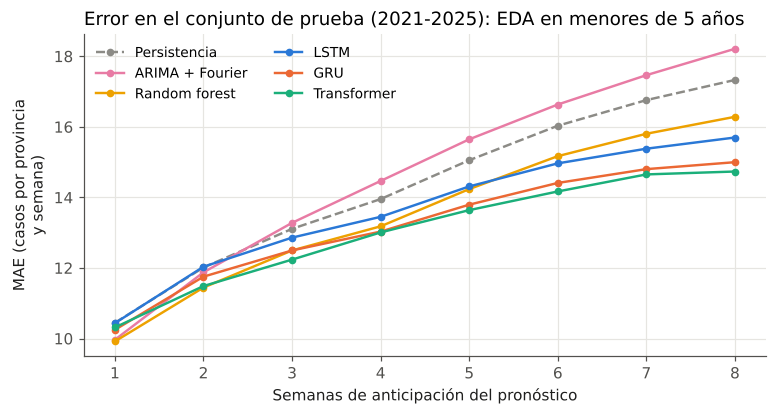

EDA terminado en 12.6 min


,MAE_val,MAE,RMSE,MAE_log,F1
modelo,,,,,
Persistencia,15.8 ± 0.0,14.3 ± 0.0,27.9 ± 0.0,0.338 ± 0.000,0.496 ± 0.000
Canal endémico (5 años),21.7 ± 0.0,20.9 ± 0.0,38.3 ± 0.0,0.460 ± 0.000,0.014 ± 0.000
ARIMA + Fourier,15.2 ± 0.0,14.7 ± 0.0,27.1 ± 0.0,0.310 ± 0.000,0.534 ± 0.000
Random forest,14.2 ± 0.0,13.6 ± 0.0,27.0 ± 0.0,0.305 ± 0.000,0.509 ± 0.003
LSTM,15.5 ± 0.2,14.0 ± 0.3,26.0 ± 0.7,0.331 ± 0.005,0.489 ± 0.010
GRU,15.2 ± 0.1,13.5 ± 0.3,24.8 ± 0.8,0.322 ± 0.005,0.487 ± 0.012
Transformer,14.9 ± 0.4,13.8 ± 0.5,25.4 ± 0.5,0.318 ± 0.011,0.476 ± 0.032


In [18]:
t = time.time()
d_eda = X.preparar(panel, "eda", cfg)
umb_eda = E.umbrales_alerta(d_eda["df"], cfg["alerta"]["percentil"])
fb_e, pb_e, tb_e = X.correr_lineas_base(d_eda, cfg, umb_eda, SEMILLAS)
fr_e, pr_e, infos_e, _ = X.correr_redes(d_eda, cfg, umb_eda, SEMILLAS, list(cfg["modelos"]), "eda",
                                        carpeta_pesos="results/pesos")
tabla_eda, _ = E.resumen_semillas(fb_e + fr_e)
tabla_eda.to_csv("results/tablas/eda_comparacion.csv")
todos_e = {**pb_e, **pr_e}
por_h_e = {X.NOMBRES[k]: E.metricas_por_horizonte(d_eda["te"].Y, todos_e[k][1])
           for k in ["persistencia", "sarimax", "random_forest", "lstm", "gru", "transformer"]}
G.error_por_horizonte(por_h_e, "eda", "EDA en menores de 5 años"); plt.show()
print(f"EDA terminado en {(time.time() - t) / 60:.1f} min")
tabla_eda

## 13. Costo computacional
Cuánto demoró cada modelo y en qué equipo se corrió.

In [19]:
hw = X.info_hardware()
costo = pd.concat([X.costo_computo(infos_r, tiempos_b).assign(objetivo="dengue"),
                   X.costo_computo(infos_e, tb_e).assign(objetivo="eda")])
costo.to_csv("results/tablas/costo_computo.csv")
minutos = (time.time() - T0) / 60
print(hw)
print(f"Tiempo total del notebook: {minutos:.1f} min "
      f"(≈ {minutos / 60:.2f} h de {'GPU' if torch.cuda.is_available() else 'CPU'})")
costo.round(1)

{'dispositivo': 'cpu', 'gpu': 'sin GPU', 'procesador': 'x86_64', 'python': '3.13.18', 'torch': '2.14.1+cu130'}
Tiempo total del notebook: 35.2 min (≈ 0.59 h de CPU)


,segundos_por_semilla,epocas,parametros,segundos_total,objetivo
modelo,,,,,
GRU,31.3,14.8,40896.0,156.3,dengue
LSTM,54.2,10.8,54336.0,270.8,dengue
Transformer,51.4,11.4,70856.0,257.2,dengue
Persistencia,NaN,NaN,NaN,0.0,dengue
Canal endémico (5 años),NaN,NaN,NaN,20.7,dengue
ARIMA + Fourier,NaN,NaN,NaN,68.1,dengue
Random forest,NaN,NaN,NaN,236.8,dengue
GRU,21.4,9.8,40896.0,107.0,eda
LSTM,13.7,10.2,54336.0,68.3,eda


## 14. Resumen

In [20]:
a = agg_den
m = lambda mod, met: a.loc[mod, (met, "mean")]
print(f"- Dengue, prueba 2021-2025: MAE LSTM = {m('LSTM','MAE'):.1f} casos/semana vs persistencia = {m('Persistencia','MAE'):.1f}, "
      f"ARIMA = {m('ARIMA + Fourier','MAE'):.1f} y random forest = {m('Random forest','MAE'):.1f}.")
print(f"- A 8 semanas la LSTM reduce el error {mejora.loc[8]:.0f} % frente a la persistencia (a 1 semana: {mejora.loc[1]:.0f} %).")
ab_ = ablac[("MAE", "mean")]
print(f"- Ablación: sin la conexión residual el MAE sube de {ab_['completo']:.1f} a {ab_['sin_residual']:.1f}; "
      f"sin clima {ab_['sin_clima']:.1f}; sin El Niño {ab_['sin_enso']:.1f}; solo casos {ab_['solo_casos']:.1f}.")
print(f"- Gradientes integrados: historia de casos {imp['Historia de casos']:.0f} %, clima {imp['Clima']:.0f} %, "
      f"El Niño {imp['El Niño']:.0f} %, estacionalidad {imp['Estacionalidad']:.0f} %.")
print(f"- Abastecimiento: nivel de servicio {s.loc['LSTM','nivel_servicio_%']:.0f} % con la LSTM vs "
      f"{s.loc['Canal endémico (5 años)','nivel_servicio_%']:.0f} % con el canal endémico, con "
      f"{s.loc['LSTM','inventario_promedio_semanal']:,.0f} vs {s.loc['Canal endémico (5 años)','inventario_promedio_semanal']:,.0f} "
      "tratamientos de inventario promedio.")

- Dengue, prueba 2021-2025: MAE LSTM = 31.8 casos/semana vs persistencia = 38.5, ARIMA = 34.5 y random forest = 29.9.
- A 8 semanas la LSTM reduce el error 29 % frente a la persistencia (a 1 semana: -6 %).
- Ablación: sin la conexión residual el MAE sube de 31.8 a 40.4; sin clima 32.0; sin El Niño 30.5; solo casos 30.4.
- Gradientes integrados: historia de casos 45 %, clima 20 %, El Niño 5 %, estacionalidad 30 %.
- Abastecimiento: nivel de servicio 72 % con la LSTM vs 45 % con el canal endémico, con 2,897 vs 5,340 tratamientos de inventario promedio.


**Limitaciones que hay que discutir en el artículo:** son datos de vigilancia, así que hay subnotificación, y la forma de clasificar la gravedad cambió en 2010. El clima se tomó en la capital de cada provincia. Las cantidades de medicamento por caso son supuestos nuestros. La simulación no considera vencimientos ni capacidad de almacén. Y la epidemia de 2023, que está en la prueba, fue más grande que todo lo que el modelo vio al entrenar.